# Carteras de inversión en acciones de EE. UU., 2003-2026

Este cuaderno contiene todo el análisis del informe. Construye un índice ponderado por capitalización con 44 acciones líderes de Estados Unidos, lo divide en 11 carteras sectoriales y estudia su desempeño, su eficiencia y su costo de capital entre septiembre de 2003 y septiembre de 2026.

| Sección | Contenido | Sección del informe |
|---|---|---|
| 1 | Índice propio, concentración, carteras sectoriales y razón de varianzas | 2 |
| 2 | Frontera eficiente | 3 |
| 3 | CAPM de Sharpe y de Black | 4 |
| 4 | Pruebas del CAPM | 5 |
| 5 | Factores y costo de capital | 6 |
| 6 | Figuras | |
| 7 | Tablas de resultados | |
| 8 | Cifras y cuadros del informe | |

Los datos están en `data/` y se describen en `data/README.md`. El cuaderno corre completo en menos de un minuto.

In [1]:
import itertools
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.lines import Line2D
from scipy import stats

from herramientas_informe import (cuadro, dec, entero, escribir, estrellas, lista, macros,
                                  matriz, pct)

DATOS = Path("../data")
TABLAS = Path("../outputs/tables")
FIGURAS = Path("../outputs/figures")
INFORME = Path("../report/latex")

INICIO, FIN = "2003-09", "2026-09"  # mes base y último mes con datos en todas las fuentes
RF_VIGENTE_ANUAL = 0.0534  # rendimiento del Tesoro a 20 años (FRED, serie DGS20)
RF_VIGENTE_FECHA = "30 de octubre de 2026"
SPREAD_CERO_BETA = 0.002  # cartera cero beta, 20 puntos base sobre la tasa libre de riesgo

ORDEN_SECTORES = ["Bienes raíces", "Comunicaciones", "Consumo discrecional", "Energía", "Finanzas",
                  "Industrial", "Materiales", "Consumo básico", "Salud", "Tecnología", "Utilidades"]

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)
resultados = {}   # cada tabla calculada; la sección 7 las guarda en outputs/tables


def leer(nombre: str) -> pd.DataFrame:
    return pd.read_csv(DATOS / nombre, index_col=0, dtype={0: str})


precios = leer("precios_mensuales.csv").loc[INICIO:FIN].astype(float)
empresas = leer("empresas.csv")
acciones = empresas["acciones_en_circulacion"].astype(float).reindex(precios.columns)
SECTOR_DE = empresas["sector"].to_dict()
largo = leer("factores_fama_french.csv").astype(float) / 100
factores = largo.loc[INICIO:FIN].copy()
momentum = leer("factor_momentum.csv")["mom"].astype(float) / 100
factores["mom"] = momentum.reindex(factores.index)
pe = leer("pe_por_sector.csv").reindex(ORDEN_SECTORES)
assert list(factores.index) == list(precios.index), "Los meses de factores y precios no coinciden"
assert factores.notna().all().all(), "Faltan datos de factores"
assert set(SECTOR_DE.values()) == set(ORDEN_SECTORES) and pe["pe_forward"].notna().all()

entrada = precios.notna().idxmax()
print(f"Precios: {len(precios)} meses ({precios.index[0]} a {precios.index[-1]}) de "
      f"{precios.shape[1]} empresas")
print("Empresas que entran después del mes base:",
      ", ".join(f"{t} ({m})" for t, m in entrada[entrada > INICIO].sort_values().items()))
print(f"Factores: {len(factores)} meses. Serie larga desde {largo.index[0]}; momentum desde "
      f"{momentum.index[0]}")

Precios: 277 meses (2003-09 a 2026-09) de 44 empresas
Empresas que entran después del mes base: GOOG (2004-08), TMUS (2007-04), V (2008-03), TSLA (2010-06), META (2012-05), ABBV (2013-01), CEG (2022-01)
Factores: 277 meses. Serie larga desde 1926-07; momentum desde 1927-01


## 1. Índice propio y carteras sectoriales

### 1.1 Capitalización, pesos e índice

La capitalización de cada empresa es su precio por su número de acciones en circulación, $MV_{jt} = P_{jt} N_j$. El rendimiento del índice pondera el rendimiento de cada acción con su peso del mes anterior,

$$r_{mt} = \sum_j w_{j,t-1}\, r_{jt}, \qquad w_{j,t-1} = \frac{MV_{j,t-1}}{\sum_i MV_{i,t-1}}, \qquad r_{jt} = \frac{P_{jt}}{P_{j,t-1}} - 1,$$

y el índice vale 100 en septiembre de 2003. Una empresa que todavía no cotiza tiene capitalización cero, así que entra al índice en cuanto tiene precios. El índice se compara con el mercado de Estados Unidos (CRSP), cuyo rendimiento es la suma de los factores Mkt-RF y RF de Kenneth French.

In [2]:
capitalizacion = precios.mul(acciones, axis=1).fillna(0.0)
pesos = capitalizacion.div(capitalizacion.sum(axis=1), axis=0)
rendimientos = (precios / precios.shift(1) - 1).fillna(0.0).iloc[1:]
rm = (pesos.shift(1).loc[rendimientos.index] * rendimientos).sum(axis=1)


def indice(r: pd.Series, base: float = 100.0) -> pd.Series:
    return pd.concat([pd.Series({INICIO: base}), base * (1 + r).cumprod()])


indice_propio = indice(rm)
r_crsp = (factores["mkt_rf"] + factores["rf"]).iloc[1:]
indice_crsp = indice(r_crsp)

meses = len(rm)
multiplo_propio, multiplo_crsp = indice_propio.iloc[-1] / 100, indice_crsp.iloc[-1] / 100
crecimiento_propio = multiplo_propio ** (12 / meses) - 1
crecimiento_crsp = multiplo_crsp ** (12 / meses) - 1
correlacion = indice_propio.corr(indice_crsp)
print(f"{meses} rendimientos mensuales. El índice propio multiplica su valor por "
      f"{multiplo_propio:.1f} ({crecimiento_propio:.2%} anual); el CRSP por {multiplo_crsp:.1f} "
      f"({crecimiento_crsp:.2%} anual)")
print(f"Correlación entre los niveles de ambos índices: {correlacion:.3f}")

indices = pd.DataFrame({"rendimiento índice propio": rm, "índice propio": indice_propio,
                        "rendimiento CRSP": r_crsp, "índice CRSP": indice_crsp})
resultados["indices"] = indices
indices

276 rendimientos mensuales. El índice propio multiplica su valor por 28.3 (15.64% anual); el CRSP por 12.2 (11.48% anual)
Correlación entre los niveles de ambos índices: 0.991


,rendimiento índice propio,índice propio,rendimiento CRSP,índice CRSP
2003-09,NaN,100.000000,NaN,100.000000
2003-10,0.023709,102.370860,0.0615,106.150000
2003-11,-0.002819,102.082244,0.0142,107.657330
2003-12,0.056742,107.874580,0.0437,112.361955
2004-01,0.018859,109.908940,0.0222,114.856391
...,...,...,...,...
2026-05,0.048787,2771.465016,0.0522,1205.402616
2026-06,-0.050888,2630.429966,-0.0078,1196.000476
2026-07,0.034665,2721.612832,-0.0028,1192.651675
2026-08,0.032749,2810.743092,0.0285,1226.642247


### 1.2 Concentración

El índice de Herfindahl es la suma de los pesos al cuadrado, $HHI_t = \sum_j w_{jt}^2$. Su inverso es el número efectivo de empresas, es decir, cuántas empresas de igual tamaño producirían la misma concentración.

In [3]:
herfindahl = pd.DataFrame({"hhi": (pesos ** 2).sum(axis=1)})
herfindahl["n_efectivo"] = 1 / herfindahl["hhi"]
herfindahl["empresas"] = (pesos > 0).sum(axis=1)
n_efectivo = herfindahl["n_efectivo"]
print(f"Número efectivo de empresas: {n_efectivo.iloc[0]:.1f} al inicio, máximo "
      f"{n_efectivo.max():.1f} ({n_efectivo.idxmax()}), mínimo {n_efectivo.min():.1f} "
      f"({n_efectivo.idxmin()}), {n_efectivo.iloc[-1]:.1f} al final; promedio "
      f"{n_efectivo.mean():.1f}")
print(f"Empresas en el índice: {herfindahl['empresas'].iloc[0]} al inicio y "
      f"{herfindahl['empresas'].iloc[-1]} al final")
resultados["concentracion"] = herfindahl
herfindahl

Número efectivo de empresas: 14.2 al inicio, máximo 25.7 (2013-09), mínimo 12.4 (2026-09), 12.4 al final; promedio 18.5
Empresas en el índice: 37 al inicio y 44 al final


,hhi,n_efectivo,empresas
fecha,,,
2003-09,0.070474,14.189532,37
2003-10,0.066999,14.925639,37
2003-11,0.065813,15.194497,37
2003-12,0.066125,15.122765,37
2004-01,0.066278,15.087888,37
...,...,...,...
2026-05,0.076051,13.149011,44
2026-06,0.072193,13.851801,44
2026-07,0.074946,13.342987,44


### 1.3 Medidas de localización y dispersión, y carteras sectoriales

Cada cartera sectorial pondera por capitalización sus cuatro empresas, con el mismo método del índice. Para los dos índices y para cada cartera se calculan medidas de localización y dispersión de los rendimientos mensuales. La semivarianza es el promedio de las desviaciones por debajo de la media al cuadrado, $\frac{1}{T}\sum_t \min(r_t - \bar r, 0)^2$, y la razón de Sharpe usa la tasa libre de riesgo promedio del período, $(\bar r - \bar r_f)/\sigma$.

In [4]:
def medidas(r: pd.Series, rf_prom: float) -> pd.Series:
    x = r.to_numpy(float)
    media, varianza = x.mean(), x.var(ddof=0)
    desviacion = np.sqrt(varianza)
    q1, q3 = np.percentile(x, [25, 75])
    return pd.Series({
        "observaciones": len(x),
        "media": media,
        "mediana": np.median(x),
        "varianza": varianza,
        "desviacion": desviacion,
        "rango": x.max() - x.min(),
        "rango_estandarizado": (x.max() - x.min()) / desviacion,
        "semirango_intercuartil": (q3 - q1) / 2,
        "semivarianza": np.mean(np.minimum(x - media, 0.0) ** 2),
        "mad": np.abs(x - media).mean(),
        "rf_promedio": rf_prom,
        "razon_sharpe": (media - rf_prom) / desviacion,
    })


rf_prom = factores["rf"].iloc[1:].mean()   # promedio de los meses con rendimiento
medidas_indices = pd.DataFrame({"Índice propio": medidas(rm, rf_prom),
                                "CRSP": medidas(r_crsp, rf_prom)})

rend_sectores, indices_sectores, medidas_sectores = {}, {}, {}
for sector in ORDEN_SECTORES:
    tickers = [t for t in capitalizacion.columns if SECTOR_DE[t] == sector]
    w = capitalizacion[tickers].div(capitalizacion[tickers].sum(axis=1), axis=0)
    rend_sectores[sector] = (w.shift(1).loc[rendimientos.index] * rendimientos[tickers]).sum(axis=1)
    indices_sectores[sector] = indice(rend_sectores[sector])
    medidas_sectores[sector] = medidas(rend_sectores[sector], rf_prom)
rend_sectores = pd.DataFrame(rend_sectores)
indices_sectores = pd.DataFrame(indices_sectores)
medidas_sectores = pd.DataFrame(medidas_sectores)

resultados.update({"medidas_indices": medidas_indices, "medidas_sectores": medidas_sectores,
                   "rendimientos_sectores": rend_sectores, "indices_sectores": indices_sectores})
display(medidas_indices)
medidas_sectores

,Índice propio,CRSP
observaciones,276.000000,276.000000
media,0.013110,0.010038
mediana,0.017636,0.014200
varianza,0.001860,0.001866
desviacion,0.043127,0.043199
rango,0.290608,0.307200
rango_estandarizado,6.738377,7.111270
semirango_intercuartil,0.024367,0.024575
semivarianza,0.001022,0.001068
mad,0.032583,0.032216


,Bienes raíces,Comunicaciones,Consumo discrecional,Energía,Finanzas,Industrial,Materiales,Consumo básico,Salud,Tecnología,Utilidades
observaciones,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000
media,0.012309,0.020693,0.019381,0.010767,0.009850,0.009975,0.013756,0.008759,0.011656,0.018423,0.010538
mediana,0.016782,0.020919,0.016228,0.011111,0.013511,0.009755,0.012014,0.008413,0.009956,0.021834,0.015828
varianza,0.003288,0.010093,0.006274,0.004045,0.003960,0.003773,0.003032,0.001322,0.001827,0.003945,0.001806
desviacion,0.057340,0.100466,0.079210,0.063598,0.062929,0.061428,0.055066,0.036366,0.042739,0.062811,0.042491
rango,0.442197,1.137949,0.468553,0.521212,0.484925,0.431090,0.367233,0.217223,0.305646,0.340470,0.242866
rango_estandarizado,7.711853,11.326738,5.915346,8.195454,7.705856,7.017797,6.669004,5.973276,7.151373,5.420517,5.715664
semirango_intercuartil,0.034843,0.049997,0.048382,0.033458,0.035181,0.032419,0.030294,0.025914,0.025083,0.046181,0.026235
semivarianza,0.001897,0.004375,0.003004,0.001946,0.002231,0.001970,0.001497,0.000699,0.000945,0.002094,0.000989
mad,0.042977,0.067364,0.061597,0.045514,0.045817,0.045503,0.041466,0.028632,0.032350,0.051695,0.033156


### 1.4 Test de razón de varianzas

El test de Lo y MacKinlay (1988) compara la varianza de los rendimientos a $q$ meses con $q$ veces la varianza mensual. Bajo una caminata aleatoria, $VR(q) = 1$. Aquí se usa $q = 6$, con observaciones traslapadas, corrección de sesgo y un error estándar robusto a heterocedasticidad. Se aplica a la empresa de mayor capitalización de cada sector al final del período, a los dos índices y a cada cartera sectorial.

In [5]:
def razon_varianzas(log_precio: pd.Series, q: int = 6) -> dict:
    x = log_precio.dropna().to_numpy(float)
    t = len(x) - 1
    d = np.diff(x)
    mu = d.mean()
    s2_1 = np.sum((d - mu) ** 2) / (t - 1)
    m = q * (t - q + 1) * (1 - q / t)
    s2_q = np.sum((x[q:] - x[:-q] - q * mu) ** 2) / m
    vr = s2_q / s2_1
    e2 = (d - mu) ** 2
    theta = sum(((2 * (q - j) / q) ** 2) * t * np.sum(e2[j:] * e2[:-j]) / e2.sum() ** 2
                for j in range(1, q))
    se_robusto = np.sqrt(theta / t)
    z_robusto = (vr - 1) / se_robusto
    return {"observaciones": t, "vr": vr, "se_robusto": se_robusto, "z_robusto": z_robusto,
            "p_robusto": 2 * stats.norm.sf(abs(z_robusto))}


ultimo = capitalizacion.iloc[-1]
mas_grande = {s: ultimo[[t for t in capitalizacion.columns if SECTOR_DE[t] == s]].idxmax()
              for s in ORDEN_SECTORES}
filas = {("Empresa más grande", f"{t} ({s})"): razon_varianzas(np.log(precios[t]))
         for s, t in mas_grande.items()}
filas[("Índice", "Índice propio")] = razon_varianzas(np.log(indice_propio))
filas[("Índice", "CRSP")] = razon_varianzas(np.log(indice_crsp))
filas.update({("Sector", s): razon_varianzas(np.log(indices_sectores[s])) for s in ORDEN_SECTORES})
tabla_rv = pd.DataFrame(filas).T
resultados["razon_varianzas"] = tabla_rv
print("Se rechaza la caminata aleatoria al 5 % en:",
      ", ".join(f"{a}: {b}" for a, b in tabla_rv.index[tabla_rv["p_robusto"] < 0.05])
      or "ninguna serie")
tabla_rv

Se rechaza la caminata aleatoria al 5 % en: Empresa más grande: NVDA (Tecnología)


observaciones        vr  se_robusto  z_robusto  p_robusto
Empresa más grande WELL (Bienes raíces)                 276.0  0.930399    0.169550  -0.410502   0.681437
                   GOOG (Comunicaciones)                265.0  0.887571    0.169549  -0.663105   0.507263
                   AMZN (Consumo discrecional)          276.0  0.847262    0.154216  -0.990413   0.321972
                   XOM (Energía)                        276.0  0.945107    0.194561  -0.282139   0.777837
                   JPM (Finanzas)                       276.0  0.843562    0.194473  -0.804422   0.421153
                   CAT (Industrial)                     276.0  1.067884    0.193705   0.350452   0.726000
                   SCCO (Materiales)                    276.0  1.088113    0.161330   0.546166   0.584952
                   WMT (Consumo básico)                 276.0  0.882847    0.146745  -0.798345   0.424670
                   LLY (Salud)                          276.0  0.828969    0.176484  -0.969106   0.332492
                   NVDA (Tecnología)                    276.0  1.330981    0.166628   1.986345   0.046995
                   NEE (Utilidades)                     276.0  0.856840    0.163487  -0.875665   0.381212
Índice             Índice propio                        276.0  1.053519    0.193484   0.276605   0.782083
                   CRSP                                 276.0  1.091181    0.204273   0.446365   0.655334
Sector             Bienes raíces                        276.0  0.976479    0.243194  -0.096717   0.922951
                   Comunicaciones                       276.0  0.781905    0.274915  -0.793319   0.427592
                   Consumo discrecional                 276.0  0.866014    0.165342  -0.810358   0.417735
                   Energía                              276.0  0.818942    0.201802  -0.897204   0.369610
                   Finanzas                             276.0  1.162802    0.281609   0.578115   0.563187
                   Industrial                           276.0  1.152509    0.217985   0.699633   0.484157
                   Materiales                           276.0  1.010062    0.181317   0.055493   0.955746
                   Consumo básico                       276.0  0.835130    0.153134  -1.076643   0.281640
                   Salud                                276.0  0.793545    0.164259  -1.256887   0.208794
                   Tecnología                           276.0  1.047855    0.170798   0.280186   0.779335
                   Utilidades                           276.0  0.686731    0.159998  -1.957957   0.050235

## 2. Frontera eficiente de las 11 carteras sectoriales

Con el vector de medias $\mu$ y la matriz de covarianzas $V$ de las carteras sectoriales se calculan $A = \iota' V^{-1}\mu$, $B = \mu' V^{-1}\mu$, $C = \iota' V^{-1}\iota$ y $D = BC - A^2$. La frontera de Markowitz (1952) es

$$\sigma_w^2 = \frac{1}{C} + \frac{C}{D}\left(\mu_w - \frac{A}{C}\right)^2,$$

la cartera de mínima varianza tiene $\mu_{MVP} = A/C$ y $\sigma_{MVP} = 1/\sqrt{C}$, y cualquier cartera de la frontera se escribe como $w = g + h\,\mu_w$, con

$$g = \frac{B V^{-1}\iota - A V^{-1}\mu}{D}, \qquad h = \frac{C V^{-1}\mu - A V^{-1}\iota}{D}.$$

Se usan los rendimientos observados y se permiten ventas en corto.

In [6]:
mu = rend_sectores.mean()
sigma = rend_sectores.std(ddof=1)
V = rend_sectores.cov()
Vi = pd.DataFrame(np.linalg.inv(V), index=V.index, columns=V.columns)
uno = np.ones(len(mu))
A = float(uno @ Vi.values @ mu.values)
B = float(mu.values @ Vi.values @ mu.values)
C = float(uno @ Vi.values @ uno)
D = B * C - A ** 2
mu_mvp, sigma_mvp = A / C, np.sqrt(1 / C)
g = pd.Series((B * Vi.values @ uno - A * Vi.values @ mu.values) / D, index=mu.index)
h = pd.Series((C * Vi.values @ mu.values - A * Vi.values @ uno) / D, index=mu.index)


def varianza_frontera(mu_p):
    return 1 / C + (C / D) * (np.asarray(mu_p) - A / C) ** 2


def pesos_frontera(mu_p: float) -> pd.Series:
    return g + h * mu_p


malla = pd.DataFrame({"mu": mu_mvp + 0.001 * np.arange(-14, 15)})
malla["sigma"] = np.sqrt(varianza_frontera(malla["mu"]))
parametros = pd.Series({"A": A, "B": B, "C": C, "D": D, "media MVP": mu_mvp,
                        "desviación MVP": sigma_mvp})
assert abs(g.sum() - 1) < 1e-10 and abs(h.sum()) < 1e-8, "g debe sumar 1 y h debe sumar 0"
print(f"Cartera de mínima varianza: media {mu_mvp:.4%} y desviación {sigma_mvp:.4%} mensuales")
resultados.update({"covarianzas": V, "parametros_frontera": parametros.to_frame("valor"),
                   "frontera": malla,
                   "g_h": pd.DataFrame({"media": mu, "desviacion": sigma, "g": g, "h": h})})
display(V)
display(parametros)
resultados["g_h"]

Cartera de mínima varianza: media 1.0794% y desviación 3.0413% mensuales


,Bienes raíces,Comunicaciones,Consumo discrecional,Energía,Finanzas,Industrial,Materiales,Consumo básico,Salud,Tecnología,Utilidades
Bienes raíces,0.003300,0.002214,0.001900,0.000929,0.001824,0.001914,0.001973,0.001101,0.001114,0.001791,0.001336
Comunicaciones,0.002214,0.010130,0.003708,0.000913,0.001539,0.001847,0.002093,0.000949,0.000735,0.002742,0.000777
Consumo discrecional,0.001900,0.003708,0.006297,0.000695,0.001670,0.001891,0.001903,0.000923,0.000865,0.003081,0.000519
Energía,0.000929,0.000913,0.000695,0.004059,0.001520,0.001910,0.001697,0.000557,0.000859,0.001109,0.000459
Finanzas,0.001824,0.001539,0.001670,0.001520,0.003975,0.002819,0.001840,0.000995,0.001262,0.001817,0.000542
Industrial,0.001914,0.001847,0.001891,0.001910,0.002819,0.003787,0.002304,0.001071,0.001310,0.001906,0.000864
Materiales,0.001973,0.002093,0.001903,0.001697,0.001840,0.002304,0.003043,0.001002,0.001011,0.001758,0.000905
Consumo básico,0.001101,0.000949,0.000923,0.000557,0.000995,0.001071,0.001002,0.001327,0.000770,0.000850,0.000789
Salud,0.001114,0.000735,0.000865,0.000859,0.001262,0.001310,0.001011,0.000770,0.001833,0.000863,0.000642
Tecnología,0.001791,0.002742,0.003081,0.001109,0.001817,0.001906,0.001758,0.000850,0.000863,0.003960,0.000703


A                   11.669092
B                    0.167461
C                 1081.114230
D                   44.877099
media MVP            0.010794
desviación MVP       0.030413
dtype: float64

,media,desviacion,g,h
Bienes raíces,0.012309,0.057444,-0.010411,-9.684674
Comunicaciones,0.020693,0.100648,-0.135901,13.659760
Consumo discrecional,0.019381,0.079354,-0.128939,15.717229
Energía,0.010767,0.063713,0.192654,-6.152346
Finanzas,0.009850,0.063044,0.212905,-13.720141
Industrial,0.009975,0.061540,0.278857,-37.538663
Materiales,0.013756,0.055166,-0.422475,39.087766
Consumo básico,0.008759,0.036432,1.384896,-90.821815
Salud,0.011656,0.042817,-0.143356,35.173051
Tecnología,0.018423,0.062925,-0.476511,48.658529


## 3. CAPM de Sharpe y de Black

### 3.1 Cartera tangente

La cartera tangente a la frontera es la de mayor razón de Sharpe, $w_q = V^{-1} z / (\iota' V^{-1} z)$, donde $z$ es el rendimiento medio de cada sector menos la tasa libre de riesgo promedio.

In [7]:
z_media = mu - rf_prom
direccion = Vi.values @ z_media.values
w_tangente = pd.Series(direccion / direccion.sum(), index=mu.index)
mu_q = float(w_tangente @ mu)
sigma_q = float(np.sqrt(w_tangente.values @ V.values @ w_tangente.values))
# La razón de Sharpe de la cartera tangente es la máxima posible, sqrt(z' V^-1 z)
sharpe_maximo = np.sqrt(z_media.values @ Vi.values @ z_media.values)
assert abs((mu_q - rf_prom) / sigma_q - sharpe_maximo) < 1e-10
resultados["cartera_tangente"] = pd.DataFrame({"z media": z_media, "peso tangente": w_tangente})
print(f"Tasa libre de riesgo promedio: {rf_prom:.6f} mensual")
print(f"Cartera tangente: media {mu_q:.4%}, desviación {sigma_q:.4%} y razón de Sharpe "
      f"{(mu_q - rf_prom) / sigma_q:.4f} mensuales")
resultados["cartera_tangente"]

Tasa libre de riesgo promedio: 0.001416 mensual
Cartera tangente: media 1.4888%, desviación 3.6453% y razón de Sharpe 0.3696 mensuales


,z media,peso tangente
Bienes raíces,0.010893,-0.154598
Comunicaciones,0.019276,0.067467
Consumo discrecional,0.017965,0.105061
Energía,0.009351,0.101057
Finanzas,0.008434,0.008638
Industrial,0.008559,-0.280023
Materiales,0.012340,0.159468
Consumo básico,0.007343,0.032730
Salud,0.010239,0.380305
Tecnología,0.017006,0.247923


### 3.2 Modelo de mercado por sector

Para cada sector se estima por mínimos cuadrados $z_{jt} = \alpha_j + \beta_j z_{mt} + \varepsilon_{jt}$, con rendimientos en exceso de la tasa libre de riesgo de cada mes. Se usan dos referencias de mercado, el índice propio y el CRSP (el factor Mkt-RF de Kenneth French).

In [8]:
def modelo_de_mercado(y: pd.DataFrame, x: pd.Series) -> pd.DataFrame:
    X = sm.add_constant(x.rename("x"))
    filas = {}
    for columna in y.columns:
        m = sm.OLS(y[columna], X).fit()
        filas[columna] = {"beta": m.params["x"], "se_beta": m.bse["x"], "t_beta": m.tvalues["x"],
                          "p_beta": m.pvalues["x"], "alfa": m.params["const"],
                          "se_alfa": m.bse["const"], "t_alfa": m.tvalues["const"],
                          "p_alfa": m.pvalues["const"], "r2": m.rsquared}
    return pd.DataFrame(filas).T


rf_meses = factores["rf"].loc[rend_sectores.index]
z_sectores = rend_sectores.sub(rf_meses, axis=0)
betas_propio = modelo_de_mercado(z_sectores, rm - rf_meses)
betas_crsp = modelo_de_mercado(z_sectores, factores["mkt_rf"].loc[z_sectores.index])
resultados.update({"betas_indice_propio": betas_propio, "betas_crsp": betas_crsp})
for nombre, tb in (("índice propio", betas_propio), ("CRSP", betas_crsp)):
    print(f"Con el {nombre}: betas mayores que 1 en {', '.join(tb.index[tb['beta'] > 1])}; "
          f"alfas significativos al 5 % en {', '.join(tb.index[tb['p_alfa'] < 0.05]) or 'ninguno'}")
display(betas_propio)
betas_crsp

Con el índice propio: betas mayores que 1 en Comunicaciones, Consumo discrecional, Tecnología; alfas significativos al 5 % en ninguno
Con el CRSP: betas mayores que 1 en Comunicaciones, Consumo discrecional, Finanzas, Industrial, Tecnología; alfas significativos al 5 % en Consumo discrecional, Salud, Tecnología, Utilidades


,beta,se_beta,t_beta,p_beta,alfa,se_alfa,t_alfa,p_alfa,r2
Bienes raíces,0.857859,0.061447,13.960921,8.017139e-34,0.000861,0.002745,0.313742,0.753956,0.415663
Comunicaciones,1.173586,0.121564,9.654066,3.596673e-19,0.005553,0.005430,1.022624,0.307388,0.253815
Consumo discrecional,1.343209,0.075929,17.690393,3.099847e-47,0.002258,0.003392,0.665634,0.506205,0.533180
Energía,0.626545,0.080724,7.761584,1.672239e-13,0.002025,0.003606,0.561453,0.574947,0.180235
Finanzas,0.994593,0.064523,15.414623,4.949025e-39,-0.003197,0.002882,-1.109114,0.268354,0.464436
Industrial,0.989400,0.061829,16.002249,3.775208e-41,-0.003011,0.002762,-1.090138,0.276610,0.483089
Materiales,0.852402,0.057378,14.855973,5.046618e-37,0.002372,0.002563,0.925491,0.355525,0.446129
Consumo básico,0.478805,0.041870,11.435406,5.120232e-25,0.001744,0.001870,0.932481,0.351909,0.323070
Salud,0.520709,0.051174,10.175188,7.732316e-21,0.004150,0.002286,1.815639,0.070519,0.274238
Tecnología,1.250197,0.045098,27.721797,1.753258e-81,0.002387,0.002014,1.184924,0.237074,0.737170


,beta,se_beta,t_beta,p_beta,alfa,se_alfa,t_alfa,p_alfa,r2
Bienes raíces,0.902135,0.058808,15.340379,9.157380e-39,0.003115,0.002592,1.201859,0.230456,0.462035
Comunicaciones,1.166433,0.121399,9.608245,5.018668e-19,0.009220,0.005350,1.723271,0.085968,0.252017
Consumo discrecional,1.197509,0.083983,14.258933,6.936623e-35,0.007640,0.003701,2.064217,0.039938,0.425958
Energía,0.748837,0.076563,9.780667,1.427127e-19,0.002895,0.003374,0.857974,0.391657,0.258781
Finanzas,1.069057,0.059688,17.910728,5.000262e-48,-0.000783,0.002631,-0.297622,0.766217,0.539336
Industrial,1.150033,0.050307,22.860270,1.887514e-65,-0.001356,0.002217,-0.611549,0.541343,0.656035
Materiales,0.981315,0.048981,20.034658,1.311164e-55,0.003879,0.002159,1.797099,0.073421,0.594307
Consumo básico,0.459738,0.042488,10.820447,5.916607e-23,0.003379,0.001873,1.804706,0.072219,0.299380
Salud,0.555350,0.049642,11.187045,3.526330e-24,0.005451,0.002188,2.491672,0.013306,0.313541
Tecnología,1.082692,0.058485,18.512329,3.468023e-50,0.007672,0.002578,2.976439,0.003177,0.555704


### 3.3 Cartera de mercado y cartera de covarianza cero

En el CAPM de Black (1972), la cartera de mercado y la cartera cero beta tienen covarianza cero. El rendimiento de la cartera cero beta no se observa, así que aquí se fija por supuesto en la tasa libre de riesgo promedio más 20 puntos base, $\mu_{cm} = \bar r_f + 0.002$. La cartera de mercado es entonces la tangente a la frontera trazada desde ese punto, con pesos proporcionales a $V^{-1}(\mu - \mu_{cm}\iota)$, y la cartera de covarianza cero es $w_{cm} = g + h\,\mu_{cm}$. La covarianza entre ambas,

$$\operatorname{Cov}(r_m, r_{cm}) = \frac{1}{C} + \frac{C}{D}\left(\mu_m - \frac{A}{C}\right)\left(\mu_{cm} - \frac{A}{C}\right),$$

debe ser cero.

In [9]:
mu_cero = rf_prom + SPREAD_CERO_BETA
direccion = Vi.values @ (mu.values - mu_cero)
w_m = pd.Series(direccion / direccion.sum(), index=mu.index)
mu_m = float(w_m @ mu)
sigma_m = float(np.sqrt(varianza_frontera(mu_m)))
w_cero = pesos_frontera(mu_cero)
sigma_cero = float(np.sqrt(varianza_frontera(mu_cero)))
covarianza = 1 / C + (C / D) * (mu_m - A / C) * (mu_cero - A / C)
print(f"Cartera de mercado: media {mu_m:.6f}, desviación {sigma_m:.6f}. Cero beta: media "
      f"{mu_cero:.6f}, desviación {sigma_cero:.6f}")
print(f"Covarianza entre ambas: {covarianza:.1e} (cero, salvo redondeo)")
resultados["carteras_mercado_y_covarianza_cero"] = pd.DataFrame({"pesos mercado": w_m,
                                                                 "pesos covarianza cero": w_cero})
resultados["carteras_mercado_y_covarianza_cero"]

Cartera de mercado: media 0.015998, desviación 0.039718. Cero beta: media 0.003416, desviación 0.047287
Covarianza entre ambas: -3.3e-19 (cero, salvo redondeo)


,pesos mercado,pesos covarianza cero
Bienes raíces,-0.165348,-0.043497
Comunicaciones,0.082630,-0.089235
Consumo discrecional,0.122507,-0.075245
Energía,0.094228,0.171636
Finanzas,-0.006592,0.166033
Industrial,-0.321693,0.150613
Materiales,0.202857,-0.288939
Consumo básico,-0.068086,1.074621
Salud,0.419349,-0.023194
Tecnología,0.301936,-0.310278


### 3.4 Betas y alfas respecto de la cartera de mercado

Como la cartera de mercado está sobre la frontera, sus betas salen de la matriz de covarianzas, $\beta_j = (V w_m)_j / (w_m' V w_m)$, sin estimar regresiones. Los alfas son $\alpha_j = (1 - \beta_j)\, z_{cm}$, donde $z_{cm} = \mu_{cm} - \bar r_f$.

In [10]:
z_cero = mu_cero - rf_prom
var_m = float(w_m.values @ V.values @ w_m.values)
covarianzas_m = pd.Series(V.values @ w_m.values, index=mu.index)
betas_mercado = pd.DataFrame({"covarianza": covarianzas_m, "beta": covarianzas_m / var_m})
betas_mercado["alfa"] = (1 - betas_mercado["beta"]) * z_cero
resultados["betas_cartera_de_mercado"] = betas_mercado
betas_mercado

,covarianza,beta,alfa
Bienes raíces,0.001115,0.706786,0.000586
Comunicaciones,0.002166,1.373128,-0.000746
Consumo discrecional,0.002002,1.268862,-0.000538
Energía,0.000922,0.584264,0.000831
Finanzas,0.000807,0.511356,0.000977
Industrial,0.000822,0.521302,0.000957
Materiales,0.001296,0.821798,0.000356
Consumo básico,0.000670,0.424660,0.001151
Salud,0.001033,0.654861,0.000690
Tecnología,0.001882,1.192701,-0.000385


## 4. Pruebas del CAPM

### 4.1 Test de Blume y Friend

Una regresión de corte transversal de los rendimientos medios en exceso sobre los betas, $\bar z_j = a + b\,\hat\beta_j + u_j$. Bajo el CAPM de Sharpe, $a = 0$ y $b = \bar z_m$, donde $\bar z_m$ es el rendimiento medio en exceso de la cartera que se usa como mercado. Se hace con los betas del índice propio (sección 3.2) y con los de la cartera de mercado (sección 3.4).

In [11]:
def blume_friend(betas: pd.Series, z: pd.Series, zm: float) -> dict:
    m = sm.OLS(z.to_numpy(float), sm.add_constant(betas.to_numpy(float))).fit()
    t_b = (m.params[1] - zm) / m.bse[1] if m.bse[1] > 1e-12 else 0.0
    return {"a": m.params[0], "b": m.params[1], "r2": m.rsquared, "se_a": m.bse[0],
            "se_b": m.bse[1], "p_a": m.pvalues[0], "p_b": m.pvalues[1],
            "p_b_igual_zm": 2 * stats.t.sf(abs(t_b), m.df_resid), "zm": zm}


zm_propio = rm.mean() - rf_prom
bf_propio = blume_friend(betas_propio["beta"], z_media, zm_propio)
bf_mercado = blume_friend(betas_mercado["beta"], z_media, mu_m - rf_prom)
resultados["blume_friend"] = pd.DataFrame({"Índice propio": bf_propio,
                                           "Cartera de mercado": bf_mercado}).T
resultados["blume_friend"]

,a,b,r2,se_a,se_b,p_a,p_b,p_b_igual_zm,zm
Índice propio,0.003272,0.009977,0.586438,2.556629e-03,2.792757e-03,2.325731e-01,6.001528e-03,0.553955,0.011694
Cartera de mercado,0.002000,0.012582,1.000000,5.293035e-18,6.246927e-18,3.242974e-128,9.336134e-135,1.000000,0.014582


### 4.2 Carteras cero beta implícitas

El intercepto $a$ es el rendimiento en exceso de la cartera cero beta coherente con cada conjunto de betas, así que su media es $\mu_{cb} = a + \bar r_f$ y sus pesos son $w_{cb} = g + h\,\mu_{cb}$.

In [12]:
mu_cb_propio = bf_propio["a"] + rf_prom
mu_cb_mercado = bf_mercado["a"] + rf_prom
cero_beta = pd.DataFrame({"con índice propio": pesos_frontera(mu_cb_propio),
                          "con cartera de mercado": pesos_frontera(mu_cb_mercado)})
resultados["carteras_cero_beta"] = cero_beta
print(f"Media de la cartera cero beta: {mu_cb_propio:.6f} con el índice propio y "
      f"{mu_cb_mercado:.6f} con la cartera de mercado")
cero_beta

Media de la cartera cero beta: 0.004689 con el índice propio y 0.003416 con la cartera de mercado


,con índice propio,con cartera de mercado
Bienes raíces,-0.055819,-0.043497
Comunicaciones,-0.071856,-0.089235
Consumo discrecional,-0.055247,-0.075245
Energía,0.163808,0.171636
Finanzas,0.148576,0.166033
Industrial,0.102852,0.150613
Materiales,-0.239207,-0.288939
Consumo básico,0.959066,1.074621
Salud,0.021558,-0.023194
Tecnología,-0.248369,-0.310278


### 4.3 Test de Gibbons, Ross y Shanken

El test GRS evalúa si el índice propio es eficiente. Compara su razón de Sharpe, $\hat{SR}_m$, con la de la cartera eficiente ex post, $\hat{SR}_q = \sqrt{z' V^{-1} z}$,

$$J = \frac{T - N - 1}{N}\left(\frac{\hat{SR}_q^2 - \hat{SR}_m^2}{1 + \hat{SR}_m^2}\right) \sim F_{N,\,T-N-1},$$

donde $T$ es el número de rendimientos mensuales y $N$ el de carteras.

In [13]:
def grs(z: pd.Series, Vi: pd.DataFrame, sr_m: float, T: int) -> dict:
    sr_q2 = float(z.values @ Vi.values @ z.values)
    N = len(z)
    J = (T - N - 1) / N * (sr_q2 - sr_m ** 2) / (1 + sr_m ** 2)
    return {"SR_q": np.sqrt(sr_q2), "SR_m": sr_m, "SR_q2": sr_q2, "SR_m2": sr_m ** 2, "T": T,
            "N": N, "J": J, "p_valor": stats.f.sf(J, N, T - N - 1),
            "critico_5": stats.f.isf(0.05, N, T - N - 1),
            "critico_10": stats.f.isf(0.10, N, T - N - 1)}


sr_m = (rm.mean() - rf_prom) / medidas_indices.loc["desviacion", "Índice propio"]
prueba_grs = grs(z_media, Vi, sr_m, T=len(rend_sectores))
resultados["grs"] = pd.Series(prueba_grs).to_frame("valor")
resultados["grs"]

,valor
SR_q,0.369562
SR_m,0.271144
SR_q2,0.136576
SR_m2,0.073519
T,276.000000
N,11.000000
J,1.409729
p_valor,0.168171
critico_5,1.825032
critico_10,1.595151


## 5. Factores y costo de capital

### 5.1 Modelo de Fama, French y Carhart

Para cada sector se estima

$$z_{jt} = \alpha_j + \beta_{jm}\, z_{mt} + \beta_{js}\, SMB_t + \beta_{jv}\, HML_t + \beta_{j,mom}\, MOM_t + \varepsilon_{jt}$$

con todas las combinaciones posibles de SMB, HML y MOM, siempre con el factor de mercado, y se elige la de menor criterio de información de Akaike (AIC).

In [14]:
OPCIONALES = ("smb", "hml", "mom")


def seleccion_aic(y: pd.Series, X: pd.DataFrame):
    mejor = None
    for k in range(len(OPCIONALES) + 1):
        for combinacion in itertools.combinations(OPCIONALES, k):
            modelo = sm.OLS(y, sm.add_constant(X[["mkt_rf", *combinacion]])).fit()
            if mejor is None or modelo.aic < mejor.aic:
                mejor = modelo
    return mejor


X = factores.loc[z_sectores.index, ["mkt_rf", "smb", "hml", "mom"]]
filas = {}
for sector in ORDEN_SECTORES:
    m = seleccion_aic(z_sectores[sector], X)
    fila = {"alfa": m.params["const"], "se_alfa": m.bse["const"], "t_alfa": m.tvalues["const"],
            "p_alfa": m.pvalues["const"]}
    for f in ("mkt_rf", *OPCIONALES):
        if f in m.params:
            fila |= {f: m.params[f], f"se_{f}": m.bse[f], f"t_{f}": m.tvalues[f],
                     f"p_{f}": m.pvalues[f]}
    filas[sector] = fila | {"aic": m.aic, "r2": m.rsquared, "observaciones": m.nobs}
cargas = pd.DataFrame(filas).T
resultados["cargas_ffc"] = cargas
print("Factores elegidos:",
      {s: [f for f in OPCIONALES if pd.notna(cargas.loc[s].get(f))] for s in ORDEN_SECTORES})
cargas

Factores elegidos: {'Bienes raíces': [], 'Comunicaciones': ['hml', 'mom'], 'Consumo discrecional': ['smb', 'hml'], 'Energía': ['hml'], 'Finanzas': ['smb', 'hml', 'mom'], 'Industrial': ['hml', 'mom'], 'Materiales': [], 'Consumo básico': ['smb', 'mom'], 'Salud': ['smb'], 'Tecnología': ['smb', 'hml'], 'Utilidades': ['smb', 'mom']}


,alfa,se_alfa,t_alfa,p_alfa,mkt_rf,se_mkt_rf,t_mkt_rf,p_mkt_rf,aic,r2,observaciones,hml,se_hml,t_hml,p_hml,mom,se_mom,t_mom,p_mom,smb,se_smb,t_smb,p_smb
Bienes raíces,0.003115,0.002592,1.201859,0.230456,0.902135,0.058808,15.340379,9.157380e-39,-961.664794,0.462035,276.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Comunicaciones,0.007780,0.005241,1.484555,0.138820,1.291452,0.124583,10.366179,1.947385e-21,-573.761584,0.294634,276.0,-0.451803,0.172429,-2.620218,9.281201e-03,0.283799,0.128810,2.203236,0.028416,NaN,NaN,NaN,NaN
Consumo discrecional,0.007794,0.003244,2.402379,0.016959,1.204013,0.078169,15.402675,6.426222e-39,-837.550953,0.565056,276.0,-0.940070,0.102703,-9.153251,1.360256e-17,NaN,NaN,NaN,NaN,0.348086,0.137095,2.539016,1.167404e-02
Energía,0.003288,0.003089,1.064389,0.288093,0.692562,0.070486,9.825546,1.048999e-19,-863.955560,0.381442,276.0,0.719198,0.097747,7.357719,2.199019e-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Finanzas,-0.000102,0.002106,-0.048454,0.961390,1.008605,0.052395,19.250165,1.227332e-52,-1077.492707,0.712406,276.0,0.690818,0.069248,9.976048,3.625679e-20,-0.226209,0.051698,-4.375585,0.000017,-0.337806,0.088733,-3.806994,1.739876e-04
Industrial,-0.000703,0.002006,-0.350496,0.726238,1.083763,0.047682,22.728946,8.012244e-65,-1103.912527,0.723304,276.0,0.462100,0.065994,7.002103,1.973232e-11,-0.095307,0.049300,-1.933213,0.054248,NaN,NaN,NaN,NaN
Materiales,0.003879,0.002159,1.797099,0.073421,0.981315,0.048981,20.034658,1.311164e-55,-1062.595777,0.594307,276.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Consumo básico,0.002136,0.001751,1.219523,0.223702,0.575795,0.043567,13.216351,3.878091e-31,-1180.313114,0.400927,276.0,NaN,NaN,NaN,NaN,0.084326,0.041208,2.046366,0.041682,-0.464167,0.073634,-6.303703,1.168219e-09
Salud,0.004800,0.002144,2.238611,0.025987,0.620900,0.051513,12.053280,4.129467e-27,-1067.190629,0.347489,276.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.340281,0.090291,-3.768720,2.010887e-04
Tecnología,0.006660,0.002296,2.900697,0.004028,1.197082,0.055321,21.638915,4.459479e-61,-1028.391360,0.652332,276.0,-0.541480,0.072684,-7.449791,1.244547e-12,NaN,NaN,NaN,NaN,-0.373870,0.097023,-3.853409,1.453743e-04


### 5.2 Costo de capital con el CAPM y con el modelo de factores

El costo de capital de cada sector es su rendimiento esperado. Con el CAPM es el beta respecto del CRSP (sección 3.2) por la prima de mercado, y con el modelo de Fama, French y Carhart (FFC) es la suma de cada carga por la prima de su factor. Las primas son los promedios de toda la historia disponible, desde julio de 1926, o desde enero de 1927 en el caso del momentum. Los alfas no entran en el rendimiento esperado. Para pasar a rendimientos anuales se usa el rendimiento vigente del Tesoro de Estados Unidos a 20 años.

In [15]:
primas = pd.Series({"mkt_rf": largo.loc[:FIN, "mkt_rf"].mean(),
                    "smb": largo.loc[:FIN, "smb"].mean(), "hml": largo.loc[:FIN, "hml"].mean(),
                    "mom": momentum.loc[:FIN].mean()})
rf_mensual = (1 + RF_VIGENTE_ANUAL) ** (1 / 12) - 1

betas_ffc = cargas[["mkt_rf", *OPCIONALES]].fillna(0.0)  # factor no elegido, carga cero
z_capm = betas_crsp["beta"] * primas["mkt_rf"]
z_ffc = (betas_ffc * primas).sum(axis=1)
esperados = pd.DataFrame({"beta_capm": betas_crsp["beta"], "z_capm": z_capm, "z_ffc": z_ffc,
                          "r_capm": z_capm + rf_mensual, "r_ffc": z_ffc + rf_mensual})
esperados["anual_capm"] = (1 + esperados["r_capm"]) ** 12 - 1
esperados["anual_ffc"] = (1 + esperados["r_ffc"]) ** 12 - 1
esperados["diferencia"] = esperados["anual_capm"] - esperados["anual_ffc"]
esperados["diferencia_abs"] = esperados["diferencia"].abs()
resultados.update({"primas": primas.to_frame("prima mensual"), "costo_de_capital": esperados})
print(f"Primas mensuales: {primas.round(6).to_dict()}; tasa libre de riesgo mensual "
      f"{rf_mensual:.6f}")
print(f"Diferencia promedio CAPM - FFC: {esperados['diferencia'].mean():.2%}; en valor absoluto "
      f"{esperados['diferencia_abs'].mean():.2%}; la mayor en "
      f"{esperados['diferencia_abs'].idxmax()} ({esperados['diferencia_abs'].max():.2%})")
esperados

Primas mensuales: {'mkt_rf': 0.006942, 'smb': 0.00163, 'hml': 0.003501, 'mom': 0.006178}; tasa libre de riesgo mensual 0.004345
Diferencia promedio CAPM - FFC: -0.14%; en valor absoluto 1.25%; la mayor en Consumo discrecional (3.64%)


,beta_capm,z_capm,z_ffc,r_capm,r_ffc,anual_capm,anual_ffc,diferencia,diferencia_abs
Bienes raíces,0.902135,0.006262,0.006262,0.010607,0.010607,0.134977,0.134977,0.000000,0.000000
Comunicaciones,1.166433,0.008097,0.009136,0.012442,0.013481,0.159950,0.174318,-0.014368,0.014368
Consumo discrecional,1.197509,0.008313,0.005634,0.012657,0.009978,0.162920,0.126533,0.036386,0.036386
Energía,0.748837,0.005198,0.007326,0.009543,0.011670,0.120719,0.149393,-0.028674,0.028674
Finanzas,1.069057,0.007421,0.007472,0.011766,0.011817,0.150691,0.151388,-0.000696,0.000696
Industrial,1.150033,0.007983,0.008552,0.012328,0.012897,0.158386,0.166226,-0.007840,0.007840
Materiales,0.981315,0.006812,0.006812,0.011157,0.011157,0.142406,0.142406,0.000000,0.000000
Consumo básico,0.459738,0.003191,0.003761,0.007536,0.008106,0.094275,0.101726,-0.007451,0.007451
Salud,0.555350,0.003855,0.003755,0.008200,0.008100,0.102957,0.101648,0.001308,0.001308
Tecnología,1.082692,0.007516,0.005804,0.011860,0.010149,0.151984,0.128819,0.023165,0.023165


### 5.3 Crecimiento implícito en la razón P/E

Con una perpetuidad creciente, $P_t = EPS_{t+1}/(r - g)$, el crecimiento que descuenta el mercado es $g = r - EPS_{t+1}/P_t$, donde $EPS_{t+1}/P_t$ es el inverso del P/E esperado del sector y $r$ su costo de capital.

In [16]:
crecimiento = pd.DataFrame({"pe_forward": pe["pe_forward"], "costo_capm": esperados["anual_capm"],
                            "costo_ffc": esperados["anual_ffc"]})
crecimiento["g_capm"] = crecimiento["costo_capm"] - 1 / crecimiento["pe_forward"]
crecimiento["g_ffc"] = crecimiento["costo_ffc"] - 1 / crecimiento["pe_forward"]
resultados["crecimiento_implicito"] = crecimiento
for col in ("g_capm", "g_ffc"):
    print(f"{col}: mayor en {crecimiento[col].idxmax()} ({crecimiento[col].max():.2%}), menor en "
          f"{crecimiento[col].idxmin()} ({crecimiento[col].min():.2%})")
crecimiento

g_capm: mayor en Industrial (12.05%), menor en Energía (2.42%)
g_ffc: mayor en Industrial (12.84%), menor en Utilidades (4.17%)


,pe_forward,costo_capm,costo_ffc,g_capm,g_ffc
Bienes raíces,29.38,0.134977,0.134977,0.100940,0.100940
Comunicaciones,17.19,0.159950,0.174318,0.101777,0.116145
Consumo discrecional,20.75,0.162920,0.126533,0.114727,0.078341
Energía,10.36,0.120719,0.149393,0.024194,0.052868
Finanzas,13.89,0.150691,0.151388,0.078697,0.079393
Industrial,26.41,0.158386,0.166226,0.120522,0.128362
Materiales,14.40,0.142406,0.142406,0.072962,0.072962
Consumo básico,21.67,0.094275,0.101726,0.048129,0.055579
Salud,19.68,0.102957,0.101648,0.052144,0.050835
Tecnología,17.33,0.151984,0.128819,0.094280,0.071115


## 6. Figuras

Cada figura se guarda en dos formatos. El PNG de `outputs/figures/` permite verla sin correr el código, y el PDF vectorial de `report/latex/figures/` es el que usa el informe. Las figuras se dibujan al tamaño en que se imprimen y no llevan título, porque el informe lo pone en el pie de figura.

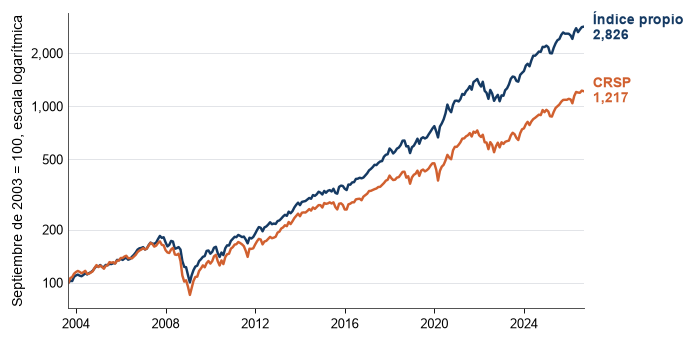

In [17]:
AZUL, NARANJA, GRIS, OSCURO = "#153A63", "#D1602F", "#7A8490", "#3A3A3A"
VERDE, CELESTE = "#2E7D5B", "#4F8FC0"
ANCHO = 6.2   # ancho del texto del informe, en pulgadas
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.6,
    "axes.edgecolor": "#444444", "axes.grid": True, "grid.color": "#DADDE1", "grid.linewidth": 0.5,
    "axes.axisbelow": True, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 0, "lines.linewidth": 1.6, "figure.dpi": 110,
    "savefig.dpi": 300, "figure.constrained_layout.use": True, "pdf.fonttype": 42,
})
FIGURAS.mkdir(parents=True, exist_ok=True)
(INFORME / "figures").mkdir(parents=True, exist_ok=True)
miles = mtick.FuncFormatter(lambda v, _: f"{v:,.0f}")
MESES_CORTOS = "ene. feb. mar. abr. may. jun. jul. ago. sep. oct. nov. dic.".split()


def fechas(periodos) -> pd.DatetimeIndex:
    return pd.to_datetime(pd.Index(periodos), format="%Y-%m")


def mes_corto(aaaamm: str) -> str:
    return f"{MESES_CORTOS[int(aaaamm[5:]) - 1]} de {aaaamm[:4]}"



def guardar(fig, nombre: str) -> None:
    fig.savefig(FIGURAS / f"{nombre}.png")
    fig.savefig(INFORME / "figures" / f"{nombre}.pdf")
    plt.show()


def anios(ax, desde: int, hasta: int, paso: int) -> None:
    ax.set_xticks(pd.to_datetime([f"{a}-01-01" for a in range(desde, hasta + 1, paso)]),
                  [str(a) for a in range(desde, hasta + 1, paso)])


# Índice propio frente al mercado, con el nombre y el valor final de cada serie junto a su línea
fig, ax = plt.subplots(figsize=(ANCHO, 3.0))
x = fechas(indice_propio.index)
for serie, color, nombre in ((indice_propio, AZUL, "Índice propio"),
                             (indice_crsp, NARANJA, "CRSP")):
    ax.plot(x, serie.values, color=color)
    ax.annotate(f"{nombre}\n{serie.iloc[-1]:,.0f}", (x[-1], serie.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", color=color, fontweight="bold", va="center",
                annotation_clip=False)
ax.set_yscale("log")
ax.set_yticks([100, 200, 500, 1000, 2000])
ax.yaxis.set_major_formatter(miles)
ax.yaxis.set_minor_locator(mtick.NullLocator())
ax.set_xlim(x[0], x[-1])
anios(ax, 2004, 2024, 4)
ax.set_ylabel("Septiembre de 2003 = 100, escala logarítmica")
ax.grid(axis="x", visible=False)
guardar(fig, "indice_propio_vs_crsp")

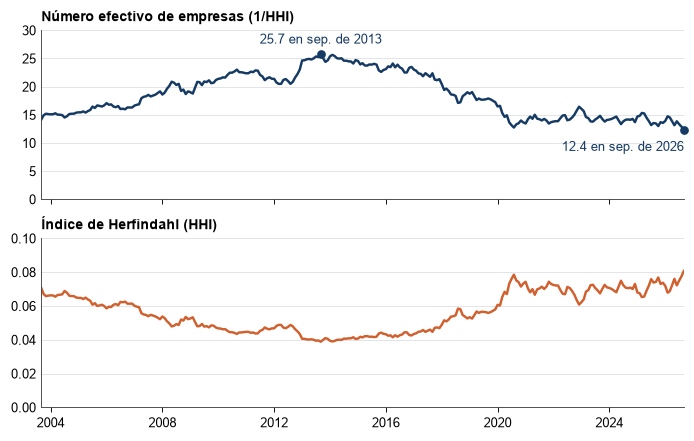

In [18]:
# Número efectivo de empresas y su inverso, el índice de Herfindahl
fig, (a, b) = plt.subplots(2, 1, figsize=(ANCHO, 3.9), sharex=True)
x = fechas(herfindahl.index)
a.plot(x, n_efectivo, color=AZUL)
maximo = n_efectivo.idxmax()
for mes, dy, alineacion in ((maximo, 7, "center"), (n_efectivo.index[-1], -14, "right")):
    a.scatter(fechas([mes]), [n_efectivo[mes]], s=22, color=AZUL, zorder=3, clip_on=False)
    a.annotate(f"{n_efectivo[mes]:.1f} en {mes_corto(mes)}", (fechas([mes])[0], n_efectivo[mes]),
               xytext=(0, dy), textcoords="offset points", ha=alineacion, color=AZUL, fontsize=8.5)
a.set_ylim(0, 30)
a.set_title("Número efectivo de empresas (1/HHI)", loc="left")
b.plot(x, herfindahl["hhi"], color=NARANJA)
b.set_ylim(0, 0.1)
b.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.2f}"))
b.set_title("Índice de Herfindahl (HHI)", loc="left")
for ax in (a, b):
    ax.set_xlim(x[0], x[-1])
    ax.grid(axis="x", visible=False)
anios(b, 2004, 2024, 4)
guardar(fig, "concentracion")

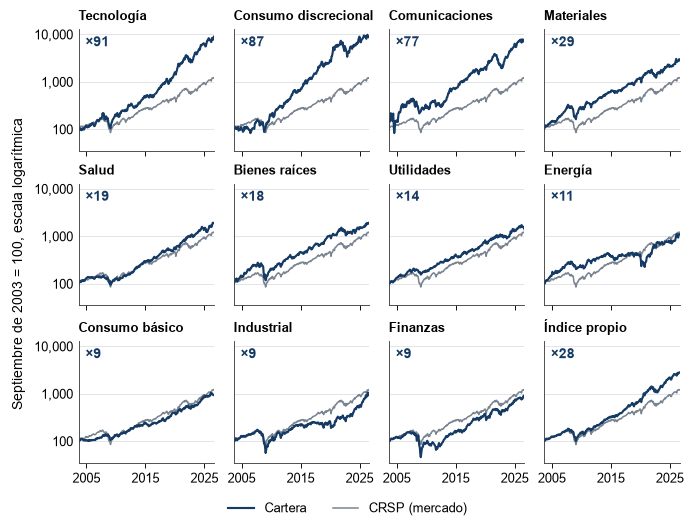

In [19]:
# Un panel por cartera sectorial, ordenados por su crecimiento, con el mercado como referencia
orden = indices_sectores.iloc[-1].sort_values(ascending=False).index
paneles = [(s, indices_sectores[s]) for s in orden] + [("Índice propio", indice_propio)]
fig, ejes = plt.subplots(3, 4, figsize=(ANCHO, 4.7), sharex=True, sharey=True)
x = fechas(indices_sectores.index)
for ax, (nombre, serie) in zip(ejes.flat, paneles):
    ax.plot(x, indice_crsp.values, color=GRIS, lw=1.0)
    ax.plot(x, serie.values, color=AZUL, lw=1.4)
    ax.set_title(nombre, loc="left", fontsize=8.5)
    ax.text(0.05, 0.86, f"×{serie.iloc[-1] / 100:.0f}", transform=ax.transAxes, color=AZUL,
            fontweight="bold", fontsize=9)
    ax.grid(axis="x", visible=False)
ejes[0, 0].set_yscale("log")
ejes[0, 0].set_yticks([100, 1000, 10000])
ejes[0, 0].yaxis.set_major_formatter(miles)
ejes[0, 0].yaxis.set_minor_locator(mtick.NullLocator())
ejes[0, 0].set_xlim(x[0], x[-1])
anios(ejes[0, 0], 2005, 2025, 10)
fig.supylabel("Septiembre de 2003 = 100, escala logarítmica", fontsize=9)
fig.legend(handles=[Line2D([], [], color=AZUL, lw=1.4, label="Cartera"),
                    Line2D([], [], color=GRIS, lw=1.0, label="CRSP (mercado)")],
           loc="outside lower center", ncol=2)
guardar(fig, "carteras_sectoriales")

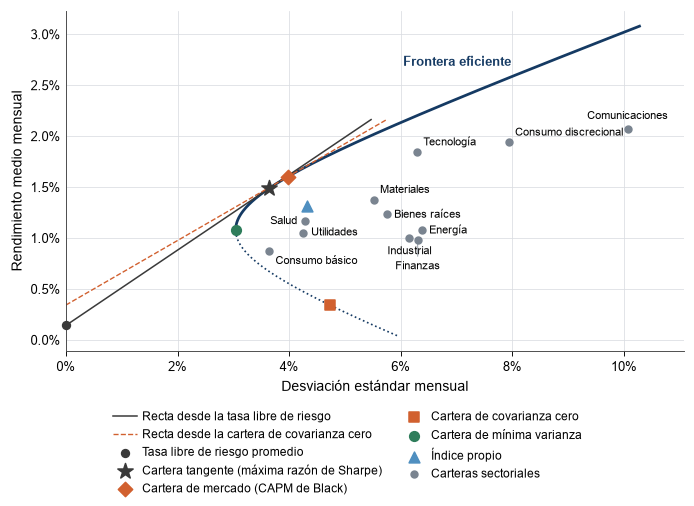

In [20]:
def etiquetar(ax, puntos: dict, evitar: tuple = (), angulos=(35, -35, 145, -145, 90, -90, 0, 180),
              ocupadas=None, **estilo) -> list:
    """Pone cada etiqueta en la posición libre más cercana a su punto, sin encimarse con otras
    etiquetas ni con los marcadores. Devuelve el espacio ocupado, para seguir etiquetando otros
    puntos del mismo gráfico."""
    ax.figure.canvas.draw()
    pintor = ax.figure.canvas.get_renderer()
    marcas = [ax.transData.transform(p) for p in (*puntos.values(), *evitar)]
    marco = ax.get_window_extent(pintor)
    ocupadas = list(ocupadas or [])
    if ax.get_legend():
        ocupadas.append(ax.get_legend().get_window_extent(pintor))

    def crear(nombre, x, y, radio, angulo, guia=None):
        dx, dy = radio * np.cos(np.radians(angulo)), radio * np.sin(np.radians(angulo))
        ha = "left" if dx > 1 else "right" if dx < -1 else "center"
        va = "bottom" if dy > 1 else "top" if dy < -1 else "center"
        return ax.annotate(nombre, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha,
                           va=va, arrowprops=guia, **({"fontsize": 7.5} | estilo))

    posiciones = [(r, a) for r in (5, 9, 14, 20, 27, 35, 44) for a in angulos]
    for nombre, (x, y) in sorted(puntos.items(), key=lambda par: par[1]):
        elegida = posiciones[0]
        for radio, angulo in posiciones:
            texto = crear(nombre, x, y, radio, angulo)
            caja = texto.get_window_extent(pintor).padded(2)
            texto.remove()
            dentro = (marco.x0 <= caja.x0 and caja.x1 <= marco.x1
                      and marco.y0 <= caja.y0 and caja.y1 <= marco.y1)
            libre = not any(caja.overlaps(o) for o in ocupadas)
            lejos = not any(caja.padded(2).contains(*m) for m in marcas)
            if dentro and libre and lejos:
                elegida = (radio, angulo)
                break
        radio, angulo = elegida
        texto = crear(nombre, x, y, radio, angulo)
        ocupadas.append(texto.get_window_extent(pintor).padded(2))
        texto.remove()
        guia = None
        if radio >= 14:
            guia = {"arrowstyle": "-", "lw": 0.5, "color": GRIS, "shrinkA": 1, "shrinkB": 3}
        crear(nombre, x, y, radio, angulo, guia)
    return ocupadas


# Frontera eficiente, carteras sectoriales con su nombre y carteras de las secciones 3 y 4
mus = np.linspace(mu_cero - 0.003, mu_mvp + 0.020, 400)
desv = np.sqrt(varianza_frontera(mus))
s_propio = medidas_indices.loc["desviacion", "Índice propio"]
m_propio = medidas_indices.loc["media", "Índice propio"]
fig, ax = plt.subplots(figsize=(ANCHO, 4.5))
ax.plot(desv[mus >= mu_mvp], mus[mus >= mu_mvp], color=AZUL, lw=1.8)
ax.plot(desv[mus < mu_mvp], mus[mus < mu_mvp], color=AZUL, lw=1.1, ls=":")
recta_rf = np.array([0, sigma_q * 1.5])  # hasta más allá de la cartera tangente
ax.plot(recta_rf, rf_prom + (mu_q - rf_prom) / sigma_q * recta_rf, color=OSCURO, lw=1.0,
        label="Recta desde la tasa libre de riesgo")
recta = np.array([0, sigma_m * 1.45])
ax.plot(recta, mu_cero + (mu_m - mu_cero) / sigma_m * recta, color=NARANJA, lw=0.9, ls="--",
        label="Recta desde la cartera de covarianza cero")
ax.scatter([0], [rf_prom], s=26, color=OSCURO, zorder=5, clip_on=False,
           label="Tasa libre de riesgo promedio")
ax.scatter([sigma_q], [mu_q], s=110, color=OSCURO, marker="*", zorder=5,
           label="Cartera tangente (máxima razón de Sharpe)")
ax.scatter([sigma_m], [mu_m], s=44, color=NARANJA, marker="D", zorder=4,
           label="Cartera de mercado (CAPM de Black)")
ax.scatter([sigma_cero], [mu_cero], s=40, color=NARANJA, marker="s", zorder=4,
           label="Cartera de covarianza cero")
ax.scatter([sigma_mvp], [mu_mvp], s=40, color=VERDE, zorder=4, label="Cartera de mínima varianza")
ax.scatter([s_propio], [m_propio], s=50, color=CELESTE, marker="^", zorder=4, label="Índice propio")
ax.scatter(sigma, mu, s=20, color=GRIS, zorder=3, label="Carteras sectoriales")
ax.set_xlim(0, max(sigma.max(), s_propio) * 1.1)
ax.set_xlabel("Desviación estándar mensual")
ax.set_ylabel("Rendimiento medio mensual")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.annotate("Frontera eficiente", (desv[-60], mus[-60]), xytext=(-8, 4), textcoords="offset points",
            ha="right", color=AZUL, fontweight="bold", fontsize=8.5)
fig.legend(loc="outside lower center", ncol=2, fontsize=8, handletextpad=0.4, columnspacing=1.6)
especiales = ((0, rf_prom), (sigma_q, mu_q), (sigma_mvp, mu_mvp), (sigma_m, mu_m),
              (sigma_cero, mu_cero), (s_propio, m_propio))
# Salud y Utilidades casi coinciden, así que su nombre va a la derecha de cada punto
juntos = {s: (sigma[s], mu[s]) for s in ("Salud", "Utilidades")}
resto = {s: (sigma[s], mu[s]) for s in ORDEN_SECTORES if s not in juntos}
ocupadas = etiquetar(ax, juntos, evitar=especiales + tuple(resto.values()),
                     angulos=(0, 180, -35, 35))
etiquetar(ax, resto, evitar=especiales + tuple(juntos.values()), ocupadas=ocupadas)
guardar(fig, "frontera_eficiente")

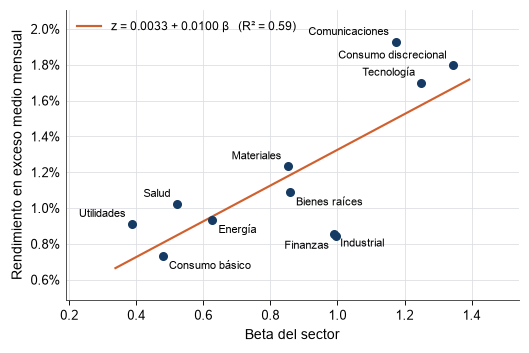

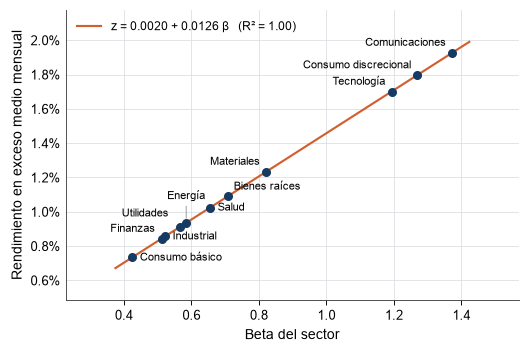

In [21]:
# Rendimiento medio en exceso de cada sector frente a su beta, con la recta de Blume y Friend
def figura_blume_friend(betas, bf, nombre):
    fig, ax = plt.subplots(figsize=(4.7, 3.1))
    ax.scatter(betas, z_media, color=AZUL, s=24, zorder=3)
    x = np.array([betas.min() - 0.05, betas.max() + 0.05])
    ax.plot(x, bf["a"] + bf["b"] * x, color=NARANJA, lw=1.4,
            label=f"z = {bf['a']:.4f} + {bf['b']:.4f} β   (R² = {bf['r2']:.2f})")
    ax.set_xlabel("Beta del sector")
    ax.set_ylabel("Rendimiento en exceso medio mensual")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
    ax.legend(loc="upper left", fontsize=8)
    ax.margins(x=0.14, y=0.14)
    # Los sectores sobre la recta llevan el nombre arriba y los demás abajo, sin taparla
    residuo = z_media - (bf["a"] + bf["b"] * betas)
    puntos = {s: (betas[s], z_media[s]) for s in ORDEN_SECTORES}
    arriba = {s: p for s, p in puntos.items() if residuo[s] > 0}
    abajo = {s: p for s, p in puntos.items() if residuo[s] <= 0}
    ocupadas = etiquetar(ax, arriba, evitar=tuple(abajo.values()),
                         angulos=(145, 35, 90, 180, 0, -145, -35, -90))
    etiquetar(ax, abajo, evitar=tuple(arriba.values()),
              angulos=(-35, -145, -90, 0, 180, 35, 145, 90), ocupadas=ocupadas)
    guardar(fig, nombre)


figura_blume_friend(betas_propio["beta"], bf_propio, "blume_friend_indice_propio")
figura_blume_friend(betas_mercado["beta"], bf_mercado, "blume_friend_mercado")

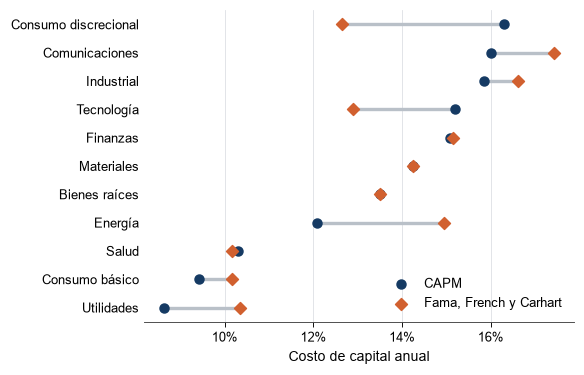

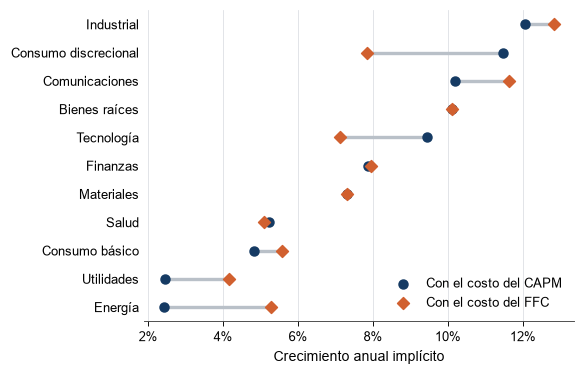

In [22]:
# Los dos modelos en la misma fila, para ver cuánto difieren en cada sector
def comparar(tabla, columna_a, columna_b, etiqueta_a, etiqueta_b, eje_x, nombre):
    orden = tabla[columna_a].sort_values().index
    y = np.arange(len(orden))
    fig, ax = plt.subplots(figsize=(5.2, 3.3))
    ax.hlines(y, tabla.loc[orden, columna_a], tabla.loc[orden, columna_b], color="#B9C0C8", lw=2.2,
              zorder=1)
    ax.scatter(tabla.loc[orden, columna_a], y, s=34, color=AZUL, zorder=3, label=etiqueta_a)
    ax.scatter(tabla.loc[orden, columna_b], y, s=30, color=NARANJA, marker="D", zorder=3,
               label=etiqueta_b)
    ax.set_yticks(y, orden)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_xlabel(eje_x)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.legend(loc="lower right")
    guardar(fig, nombre)


comparar(esperados, "anual_capm", "anual_ffc", "CAPM", "Fama, French y Carhart",
         "Costo de capital anual", "costo_de_capital")
comparar(crecimiento, "g_capm", "g_ffc", "Con el costo del CAPM", "Con el costo del FFC",
         "Crecimiento anual implícito", "crecimiento_implicito")

## 7. Tablas de resultados

Cada tabla calculada se guarda como CSV en `outputs/tables/`, numerada en el orden del cuaderno.

In [23]:
TABLAS.mkdir(parents=True, exist_ok=True)
for viejo in TABLAS.glob("*.csv"):
    viejo.unlink()
for i, (nombre, tabla) in enumerate(resultados.items(), start=1):
    tabla.to_csv(TABLAS / f"{i:02d}_{nombre}.csv", encoding="utf-8-sig")
print(f"{len(resultados)} tablas guardadas en {TABLAS}:", ", ".join(resultados))

23 tablas guardadas en ..\outputs\tables: indices, concentracion, medidas_indices, medidas_sectores, rendimientos_sectores, indices_sectores, razon_varianzas, covarianzas, parametros_frontera, frontera, g_h, cartera_tangente, betas_indice_propio, betas_crsp, carteras_mercado_y_covarianza_cero, betas_cartera_de_mercado, blume_friend, carteras_cero_beta, grs, cargas_ffc, primas, costo_de_capital, crecimiento_implicito


## 8. Cifras y cuadros del informe

Esta sección no calcula nada nuevo. Escribe los resultados en el formato del informe (`report/latex/`). Cada número del texto es una macro, por ejemplo `\cifraCagrPropio`, definida en `tables/cifras.tex`, y cada cuadro es un archivo `.tex` de la misma carpeta. Así ninguna cifra del informe se escribe a mano.

El texto del informe también afirma cosas como «tecnología tiene la razón de Sharpe más alta entre los sectores». La primera celda comprueba esas afirmaciones con los datos. Si alguna deja de cumplirse, el cuaderno se detiene e indica cuál hay que revisar.

In [24]:
TEX = INFORME / "tables"
ms = medidas_sectores.T
sharpe = ms["razon_sharpe"]
sharpe_propio = medidas_indices.loc["razon_sharpe", "Índice propio"]
media, mediana = medidas_indices.loc["media"], medidas_indices.loc["mediana"]
n_ef = herfindahl["n_efectivo"]
peso_sector_final = pesos.iloc[-1].groupby(SECTOR_DE).sum()
alfas_diez = betas_propio.loc[betas_propio["p_alfa"] < 0.10, "alfa"]

afirmaciones = {
    "La cartera llega a tener 44 empresas y las tiene todas al final":
        herfindahl["empresas"].iloc[-1] == 44 and herfindahl["empresas"].max() == 44,
    "El número efectivo de empresas cierra en su mínimo":
        n_ef.idxmin() == n_ef.index[-1],
    "Tecnología, comunicaciones y consumo discrecional son los sectores de más peso al final":
        set(peso_sector_final.nlargest(3).index) == {"Tecnología", "Comunicaciones",
                                                     "Consumo discrecional"},
    "El índice propio tiene mayor media y mayor mediana que el CRSP":
        media["Índice propio"] > media["CRSP"] and mediana["Índice propio"] > mediana["CRSP"],
    "Tecnología tiene la mayor razón de Sharpe de los sectores, sin superar al índice propio":
        sharpe.idxmax() == "Tecnología" and sharpe_propio > sharpe.max(),
    "Tecnología, salud, consumo discrecional y materiales tienen las mejores razones de Sharpe":
        list(sharpe.nlargest(4).index) == ["Tecnología", "Salud", "Consumo discrecional",
                                           "Materiales"],
    "Finanzas, industrial y energía tienen las razones de Sharpe más bajas":
        list(sharpe.nsmallest(3).index) == ["Finanzas", "Industrial", "Energía"],
    "Comunicaciones tiene la mayor media, la mayor varianza y el mayor rango":
        ms["media"].idxmax() == ms["varianza"].idxmax() == ms["rango"].idxmax() == "Comunicaciones",
    "Tecnología tiene la mayor mediana y el menor rango estandarizado":
        ms["mediana"].idxmax() == ms["rango_estandarizado"].idxmin() == "Tecnología",
    "Consumo básico es el sector más defensivo":
        all(ms[c].idxmin() == "Consumo básico" for c in ("varianza", "semivarianza", "mad")),
    "Bienes raíces e industrial tienen peso negativo en la cartera tangente":
        set(w_tangente.index[w_tangente < 0]) == {"Bienes raíces", "Industrial"},
    "La cartera de mercado y la de covarianza cero no covarían":
        abs(covarianza) < 1e-12,
    "Todas las betas son positivas y significativas al 1 %":
        all((tb["beta"] > 0).all() and (tb["p_beta"] < 0.01).all()
            for tb in (betas_propio, betas_crsp)),
    "Con el índice propio ningún alfa es significativo al 5 % y los dos del 10 % son positivos":
        (betas_propio["p_alfa"] >= 0.05).all() and len(alfas_diez) == 2 and (alfas_diez > 0).all(),
    "Con el CRSP los alfas significativos son positivos":
        (betas_crsp.loc[betas_crsp["p_alfa"] < 0.10, "alfa"] > 0).all(),
    "Con el índice propio, a no difiere de cero y b es significativo pero no difiere de la prima":
        bf_propio["a"] > 0 and bf_propio["p_a"] > 0.05 and bf_propio["b"] < bf_propio["zm"]
        and bf_propio["p_b"] < 0.05 and bf_propio["p_b_igual_zm"] > 0.05,
    "Con la cartera de mercado el ajuste es exacto y la cartera cero beta es la de covarianza cero":
        abs(bf_mercado["a"] - z_cero) < 1e-10 and abs(bf_mercado["r2"] - 1) < 1e-10
        and abs(mu_cb_mercado - mu_cero) < 1e-10,
    "El test GRS no rechaza la eficiencia del índice propio ni al 10 %":
        prueba_grs["J"] < prueba_grs["critico_10"],
    "Los alfas significativos del modelo de factores son positivos":
        (cargas.loc[cargas["p_alfa"] < 0.05, "alfa"] > 0).all(),
    "Consumo discrecional tiene la mayor carga en SMB y consumo básico la menor":
        cargas["smb"].idxmax() == "Consumo discrecional"
        and cargas["smb"].idxmin() == "Consumo básico",
    "Energía y finanzas tienen las mayores cargas en HML y consumo discrecional la menor":
        set(cargas["hml"].nlargest(2).index) == {"Energía", "Finanzas"}
        and cargas["hml"].idxmin() == "Consumo discrecional",
    "Comunicaciones tiene la mayor carga en MOM y finanzas la menor":
        cargas["mom"].idxmax() == "Comunicaciones" and cargas["mom"].idxmin() == "Finanzas",
    "El mayor crecimiento implícito es el del mismo sector con ambos modelos":
        crecimiento["g_capm"].idxmax() == crecimiento["g_ffc"].idxmax(),
}
fallas = [texto for texto, cumple in afirmaciones.items() if not cumple]
assert not fallas, "Estas afirmaciones del informe ya no se cumplen. " + "; ".join(fallas)
print(f"Las {len(afirmaciones)} afirmaciones del texto se cumplen.")

Las 23 afirmaciones del texto se cumplen.


### Las cifras del texto

In [25]:
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre",
         "octubre", "noviembre", "diciembre"]


def fecha_larga(aaaamm: str) -> str:
    return f"{MESES[int(aaaamm[5:]) - 1]} de {aaaamm[:4]}"


rv_empresas = tabla_rv.loc["Empresa más grande"]
rechazos = rv_empresas.index[rv_empresas["p_robusto"] < 0.05]
fila_util = tabla_rv.loc[("Sector", "Utilidades")]
# El texto dice que solo una serie, una de las empresas, rechaza la caminata aleatoria
assert len(rechazos) == 1 and (tabla_rv["p_robusto"] < 0.05).sum() == 1

comunicaciones = [t for t in precios.columns if SECTOR_DE[t] == "Comunicaciones"]
solo_netflix = precios[comunicaciones].notna().sum(axis=1) == 1
# Al inicio, Netflix es la única empresa de comunicaciones en el índice
assert solo_netflix.iloc[0] and precios.loc[solo_netflix, "NFLX"].notna().all()
ultimo_solo_netflix = solo_netflix[solo_netflix].index[-1]

cifras = {
    # Período y desempeño
    "Fin": fecha_larga(FIN),
    "RfFecha": RF_VIGENTE_FECHA,
    "RfForwardDecimal": f"{RF_VIGENTE_ANUAL:.4f}",
    "SoloNetflixHasta": fecha_larga(ultimo_solo_netflix),
    "NetflixOctubre": f"{100 * rendimientos.loc['2003-10', 'NFLX']:.1f}",
    "Meses": str(meses),
    "MultiploPropio": f"{multiplo_propio:.1f}",
    "MultiploCrsp": f"{multiplo_crsp:.1f}",
    "CagrPropio": f"{100 * crecimiento_propio:.2f}",
    "CagrCrsp": f"{100 * crecimiento_crsp:.2f}",
    "SharpePropio": f"{sharpe_propio:.4f}",
    "SharpeCrsp": f"{medidas_indices.loc['razon_sharpe', 'CRSP']:.4f}",
    "SharpeTecnologia": f"{ms.loc['Tecnología', 'razon_sharpe']:.4f}",
    "CorrIndices": f"{correlacion:.3f}",
    # Concentración
    "NefInicio": f"{n_ef.iloc[0]:.1f}",
    "NefMaximo": f"{n_ef.max():.1f}",
    "NefMaximoFecha": fecha_larga(n_ef.idxmax()),
    "NefFinal": f"{n_ef.iloc[-1]:.1f}",
    "NefPromedio": f"{n_ef.mean():.1f}",
    # Razón de varianzas
    "VrRechazo": rechazos[0],
    "VrRechazoValor": f"{rv_empresas.loc[rechazos[0], 'vr']:.2f}",
    "VrUtilidadesP": f"{fila_util['p_robusto']:.3f}",
    # Frontera y CAPM
    "RfProm": f"{rf_prom:.6f}",
    "MuMvpPct": f"{100 * mu_mvp:.2f}",
    "SigmaMvpPct": f"{100 * sigma_mvp:.2f}",
    "MuTangentePct": f"{100 * mu_q:.2f}",
    "SigmaTangentePct": f"{100 * sigma_q:.2f}",
    "MuCero": f"{mu_cero:.6f}",
    "MuMercado": f"{mu_m:.6f}",
    "SigmaMercado": f"{sigma_m:.6f}",
    "SigmaCero": f"{sigma_cero:.6f}",
    "ZCero": f"{z_cero:.4f}",
    "BetaMayorUnoPropio": lista(betas_propio.index[betas_propio["beta"] > 1]),
    "AlfaDiezPropio": lista(betas_propio.index[betas_propio["p_alfa"] < 0.10]),
    "RdosAltoPropio": lista(betas_propio.index[betas_propio["r2"] >= 0.5]),
    "BetaMayorUnoCrsp": lista(betas_crsp.index[betas_crsp["beta"] > 1]),
    "AlfaCincoCrsp": lista(betas_crsp.index[betas_crsp["p_alfa"] < 0.05]),
    "NumAlfaCincoCrsp": str(int((betas_crsp["p_alfa"] < 0.05).sum())),
    "AlfaDiezSoloCrsp": lista(betas_crsp.index[betas_crsp["p_alfa"].between(0.05, 0.10)]),
    "RdosAltoCrsp": lista(betas_crsp.index[betas_crsp["r2"] >= 0.5]),
    # Pruebas del CAPM
    "ZmUno": f"{bf_propio['zm']:.4f}",
    "BfAUno": f"{bf_propio['a']:.4f}",
    "BfBUno": f"{bf_propio['b']:.4f}",
    "BfPaUno": f"{bf_propio['p_a']:.3f}",
    "BfPbzUno": f"{bf_propio['p_b_igual_zm']:.3f}",
    "BfPbUno": f"{bf_propio['p_b']:.3f}",
    "BfADos": f"{bf_mercado['a']:.4f}",
    "BfBDos": f"{bf_mercado['b']:.4f}",
    "ZmDos": f"{bf_mercado['zm']:.4f}",
    "MuCbUno": f"{mu_cb_propio:.6f}",
    "MuCbDos": f"{mu_cb_mercado:.6f}",
    "GrsT": str(prueba_grs["T"]),
    "GrsN": str(prueba_grs["N"]),
    "GrsGl": str(prueba_grs["T"] - prueba_grs["N"] - 1),
    "GrsSrq": f"{prueba_grs['SR_q']:.4f}",
    "GrsSrm": f"{prueba_grs['SR_m']:.4f}",
    "GrsJ": f"{prueba_grs['J']:.4f}",
    "GrsCincoPct": f"{prueba_grs['critico_5']:.4f}",
    "GrsDiezPct": f"{prueba_grs['critico_10']:.4f}",
    "GrsP": f"{prueba_grs['p_valor']:.3f}",
    # Factores y costo de capital
    "AlfaCincoFfc": lista(cargas.index[cargas["p_alfa"] < 0.05]),
    "SmbMax": lista([cargas["smb"].idxmax()]), "SmbMin": lista([cargas["smb"].idxmin()]),
    "HmlMax": lista([cargas["hml"].idxmax()]), "HmlMin": lista([cargas["hml"].idxmin()]),
    "MomMax": lista([cargas["mom"].idxmax()]), "MomMin": lista([cargas["mom"].idxmin()]),
    "RfForward": f"{100 * RF_VIGENTE_ANUAL:.2f}",
    "RfForwardMensual": f"{rf_mensual:.6f}",
    "DifPromedio": f"{100 * esperados['diferencia'].mean():.2f}".replace("-", "$-$"),
    "DifAbsoluta": f"{100 * esperados['diferencia_abs'].mean():.2f}",
    "DifMayorSector": lista([esperados["diferencia_abs"].idxmax()]),
    "DifMayorValor": f"{100 * esperados['diferencia_abs'].max():.2f}",
    "CostoMaxSector": lista([esperados["anual_capm"].idxmax()]),
    "CostoMaxValor": f"{100 * esperados['anual_capm'].max():.1f}",
    "CostoMinSector": lista([esperados["anual_capm"].idxmin()]),
    "CostoMinValor": f"{100 * esperados['anual_capm'].min():.1f}",
    "CrecMaxCapm": lista([crecimiento["g_capm"].idxmax()]),
    "CrecMaxCapmValor": f"{100 * crecimiento['g_capm'].max():.1f}",
    "CrecMinCapm": lista([crecimiento["g_capm"].idxmin()]),
    "CrecMinCapmValor": f"{100 * crecimiento['g_capm'].min():.1f}",
    "CrecMaxFfc": lista([crecimiento["g_ffc"].idxmax()]),
    "CrecMaxFfcValor": f"{100 * crecimiento['g_ffc'].max():.1f}",
    "CrecMinFfc": lista([crecimiento["g_ffc"].idxmin()]),
    "CrecMinFfcValor": f"{100 * crecimiento['g_ffc'].min():.1f}",
}
escribir(TEX, "cifras", macros(cifras))
pd.Series(cifras, name="como aparece en el informe").to_frame()

,como aparece en el informe
Fin,septiembre de 2026
RfFecha,30 de octubre de 2026
RfForwardDecimal,0.0534
SoloNetflixHasta,julio de 2004
NetflixOctubre,70.7
...,...
CrecMinCapmValor,2.4
CrecMaxFfc,industrial
CrecMaxFfcValor,12.8
CrecMinFfc,utilidades


### Los cuadros

In [26]:
d2, d3, d4, d5, p2 = dec(2), dec(3), dec(4), dec(5), pct(2)
texto = str   # columnas ya escritas como texto
CHICA = r"\footnotesize"   # letra de los cuadros anchos


def con_suma(tabla: pd.DataFrame) -> pd.DataFrame:
    return pd.concat([tabla, tabla.sum().to_frame("Suma de pesos").T])


def con_estrellas(sector: str, factor: str) -> str:
    coef, p = cargas.loc[sector].get(factor), cargas.loc[sector].get(f"p_{factor}")
    return "" if pd.isna(coef) else d4(coef) + estrellas(p)


# Sección 2 del informe
etiquetas = {"observaciones": "Observaciones", "media": "Media", "mediana": "Mediana",
             "varianza": "Varianza", "desviacion": "Desviación estándar", "rango": "Rango",
             "rango_estandarizado": "Rango estandarizado",
             "semirango_intercuartil": "Semirrango intercuartil", "semivarianza": "Semivarianza",
             "mad": "Desviación media absoluta", "razon_sharpe": "Razón de Sharpe"}
indices_tx = medidas_indices.loc[list(etiquetas)].copy().astype(object)
for c in indices_tx.columns:
    indices_tx[c] = [entero(v) if k == "observaciones" else f"{v:.6f}"
                     for k, v in medidas_indices.loc[list(etiquetas), c].items()]
indices_tx.index = [etiquetas[k] for k in indices_tx.index]
escribir(TEX, "medidas_indices",
         cuadro(indices_tx, [("Índice propio", "Índice propio", texto), ("CRSP", "CRSP", texto)],
                "Medidas de los rendimientos mensuales del índice propio y del CRSP",
                "tab:medidas_indices", primera="Medida",
                nota=f"Rendimientos mensuales de octubre de 2003 a {fecha_larga(FIN)}."))

escribir(TEX, "medidas_sectores",
         cuadro(ms,
                [("Media", "media", d4), ("Mediana", "mediana", d4),
                 ("Desv. est.", "desviacion", d4), ("Semivar.", "semivarianza", d5),
                 ("MAD", "mad", d4), ("Rango est.", "rango_estandarizado", d2),
                 ("Sharpe", "razon_sharpe", d3)],
                "Medidas de los rendimientos mensuales de las carteras sectoriales",
                "tab:medidas_sectores",
                nota="Desv. est. es la desviación estándar; Semivar., la semivarianza por debajo "
                     "de la media; MAD, la desviación media absoluta; Rango est., el rango entre "
                     "la desviación estándar, y Sharpe, la razón de Sharpe mensual."))

rv_tx = tabla_rv.copy()
rv_tx.index = [s for _, s in tabla_rv.index]
escribir(TEX, "razon_varianzas",
         cuadro(rv_tx,
                [("VR(6)", "vr", d3), ("Z robusto", "z_robusto", d2),
                 ("Valor $p$", "p_robusto", d3)],
                "Test de razón de varianzas de Lo y MacKinlay ($q = 6$)", "tab:razon_varianzas",
                primera="Serie", separar_despues=(10, 12),
                nota="Empresa de mayor capitalización de cada sector al final del período, índices "
                     "y carteras sectoriales, en logaritmos. El estadístico es robusto a "
                     "heterocedasticidad y la hipótesis nula es una caminata aleatoria, "
                     "$VR(6) = 1$."))

# Sección 3
ABREV = {"Bienes raíces": "B. raíces", "Comunicaciones": "Comun.",
         "Consumo discrecional": "C. discr.", "Energía": "Energía", "Finanzas": "Finanzas",
         "Industrial": "Indust.", "Materiales": "Mater.", "Consumo básico": "C. básico",
         "Salud": "Salud", "Tecnología": "Tecnol.", "Utilidades": "Utilid."}
escribir(TEX, "covarianzas",
         matriz(1000 * V,
                "Matriz de varianzas y covarianzas de las carteras sectoriales (multiplicada "
                "por 1000)", "tab:covarianzas", d2, abreviaturas=ABREV,
                nota="Rendimientos mensuales. La diagonal, sombreada, contiene las varianzas."))
parametros_tx = pd.DataFrame({"valor": [f"{A:.4f}", f"{B:.6f}", f"{C:.4f}", f"{D:.4f}",
                                        f"{mu_mvp:.6f}", f"{sigma_mvp:.6f}"]},
                             index=["$A$", "$B$", "$C$", "$D$", r"$\mu_{MVP}$", r"$\sigma_{MVP}$"])
escribir(TEX, "frontera",
         cuadro(parametros_tx, [("Valor", "valor", texto)],
                "Parámetros de la frontera y cartera de mínima varianza", "tab:frontera",
                primera="Parámetro"))
escribir(TEX, "g_h", cuadro(pd.DataFrame({"mu": mu, "sigma": sigma, "g": g, "h": h}),
         [(r"$\mu$", "mu", d4), (r"$\sigma$", "sigma", d4), ("$g$", "g", d4), ("$h$", "h", d3)],
         "Media, desviación estándar y vectores $g$ y $h$ de cada cartera sectorial", "tab:g_h",
         nota="Los pesos de $g$ suman 1 y los de $h$ suman 0."))

# Sección 4
tras_sectores = (len(ORDEN_SECTORES) - 1,)   # línea divisoria antes de la fila de la suma
escribir(TEX, "tangente",
         cuadro(con_suma(pd.DataFrame({"peso": w_tangente})).assign(z=list(z_media) + [np.nan]),
                [("$z$ medio", "z", d4), ("Peso", "peso", d4)],
                "Rendimiento medio en exceso y pesos de la cartera tangente", "tab:tangente",
                separar_despues=tras_sectores))
columnas_mm = [(r"$\beta$", "beta", d3), ("Error", "se_beta", d3), ("$t$", "t_beta", d2),
               ("Valor $p$", "p_beta", d3), (r"$\alpha$", "alfa", d4), ("Error", "se_alfa", d4),
               ("$t$", "t_alfa", d2), ("Valor $p$", "p_alfa", d3), ("$R^2$", "r2", d3)]
escribir(TEX, "betas_propio",
         cuadro(betas_propio, columnas_mm, "Modelo de mercado con el índice propio",
                "tab:betas_propio", letra=CHICA,
                nota=f"Regresión de $z_{{jt}}$ sobre $z_{{mt}}$ por mínimos cuadrados ordinarios, "
                     f"con {meses} meses."))
escribir(TEX, "betas_crsp",
         cuadro(betas_crsp, columnas_mm, "Modelo de mercado con el CRSP", "tab:betas_crsp",
                letra=CHICA,
                nota=f"Regresión de $z_{{jt}}$ sobre el factor Mkt-RF por mínimos cuadrados "
                     f"ordinarios, con {meses} meses."))
escribir(TEX, "carteras_mercado",
         cuadro(con_suma(pd.DataFrame({"m": w_m, "c": w_cero})),
                [("Mercado", "m", d4), ("Covarianza cero", "c", d4)],
                "Pesos de la cartera de mercado y de la cartera de covarianza cero",
                "tab:carteras_mercado", separar_despues=tras_sectores))
escribir(TEX, "betas_teoricas",
         cuadro(betas_mercado,
                [("Covarianza", "covarianza", d5), (r"$\beta$", "beta", d3),
                 (r"$\alpha$", "alfa", d5)], "Betas y alfas respecto de la cartera de mercado",
                "tab:betas_teoricas"))

# Sección 5
bf = pd.DataFrame({"Índice propio": bf_propio, "Cartera de mercado": bf_mercado}).T
bf.loc["Cartera de mercado", ["p_a", "p_b", "p_b_igual_zm"]] = np.nan  # el ajuste es exacto
escribir(TEX, "blume_friend",
         cuadro(bf,
                [("$a$", "a", d4), ("$b$", "b", d4), ("$R^2$", "r2", d3), ("$p(a=0)$", "p_a", d3),
                 ("$p(b=0)$", "p_b", d3), (r"$p(b=\bar z_m)$", "p_b_igual_zm", d3),
                 (r"$\bar z_m$", "zm", d4)], "Test de Blume y Friend", "tab:blume_friend",
                primera="Betas",
                nota="Con la cartera de mercado el ajuste es exacto por construcción, así que los "
                     "valores $p$ no aplican."))
escribir(TEX, "cero_beta",
         cuadro(con_suma(pd.DataFrame({"a": pesos_frontera(mu_cb_propio),
                                       "b": pesos_frontera(mu_cb_mercado)})),
                [("Con el índice propio", "a", d4), ("Con la cartera de mercado", "b", d4)],
                "Pesos de las carteras cero beta", "tab:cero_beta", separar_despues=tras_sectores))

# Sección 6
cargas_tx = pd.DataFrame({f: [con_estrellas(s, f) for s in cargas.index]
                          for f in ("alfa", "mkt_rf", "smb", "hml", "mom")}, index=cargas.index)
cargas_tx["r2"] = cargas["r2"]
escribir(TEX, "cargas_ffc",
         cuadro(cargas_tx,
                [(r"$\alpha$", "alfa", texto), ("Mkt-RF", "mkt_rf", texto), ("SMB", "smb", texto),
                 ("HML", "hml", texto), ("MOM", "mom", texto), ("$R^2$", "r2", d3)],
                "Cargas del modelo de Fama, French y Carhart", "tab:cargas_ffc",
                nota="Mejor modelo de cada sector según el criterio de Akaike; una celda vacía "
                     "indica que el factor no entró. * $p<0.10$, ** $p<0.05$, *** $p<0.01$."))
escribir(TEX, "primas",
         cuadro(pd.DataFrame({"prima": primas.values,
                              "desde": ["julio de 1926"] * 3 + ["enero de 1927"]},
                             index=["Mercado (Mkt-RF)", "SMB", "HML", "MOM"]),
                [("Prima mensual", "prima", pct(4)), ("Desde", "desde", texto)],
                "Primas de largo plazo de los factores", "tab:primas", primera="Factor",
                alineacion="lrl", nota=f"Promedios mensuales hasta {fecha_larga(FIN)}."))
escribir(TEX, "costo_capital",
         cuadro(esperados,
                [(r"$\beta$ CAPM", "beta_capm", d3), ("E($z$) CAPM", "z_capm", p2),
                 ("E($z$) FFC", "z_ffc", p2), ("Costo CAPM", "anual_capm", p2),
                 ("Costo FFC", "anual_ffc", p2),
                 ("Diferencia", "diferencia", lambda x: d2(100 * x))],
                "Rendimiento esperado y costo de capital anual por sector", "tab:costo_capital",
                letra=CHICA,
                nota="E($z$) es el rendimiento esperado en exceso mensual, y el costo, el "
                     "rendimiento esperado anual con la tasa del Tesoro a 20 años. La diferencia "
                     "es el costo con el CAPM menos el costo con el FFC, en puntos porcentuales."))
escribir(TEX, "crecimiento",
         cuadro(crecimiento,
                [("P/E esperado", "pe_forward", d2), ("Costo CAPM", "costo_capm", p2),
                 ("Costo FFC", "costo_ffc", p2), ("$g$ CAPM", "g_capm", p2),
                 ("$g$ FFC", "g_ffc", p2)], "Crecimiento anual implícito en el P/E esperado",
                "tab:crecimiento", nota="P/E esperado de cada sector según Finviz."))

print("Cuadros:", ", ".join(sorted(p.stem for p in TEX.glob("*.tex"))))
print("Figuras:", ", ".join(sorted(p.stem for p in (INFORME / "figures").glob("*.pdf"))))

Cuadros: betas_crsp, betas_propio, betas_teoricas, blume_friend, cargas_ffc, carteras_mercado, cero_beta, cifras, costo_capital, covarianzas, crecimiento, frontera, g_h, medidas_indices, medidas_sectores, primas, razon_varianzas, tangente


Figuras: blume_friend_indice_propio, blume_friend_mercado, carteras_sectoriales, concentracion, costo_de_capital, crecimiento_implicito, frontera_eficiente, indice_propio_vs_crsp
